# Project 1, Parts 3 and 5 + Selected Component

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/project_1
!ls data

Mounted at /content/drive
/content/drive/MyDrive/project_1
dataset_a_test.csv   dataset_b_test.csv  dataset_c_train.csv
dataset_a_train.csv  dataset_c_test.csv


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

DEVICE: cuda


In [3]:
SOURCE_A_TRAIN = pd.read_csv("./data/dataset_a_train.csv")
SOURCE_A_TEST = pd.read_csv("./data/dataset_a_test.csv")
SOURCE_B_TEST = pd.read_csv("./data/dataset_b_test.csv")
print(SOURCE_A_TRAIN.shape, SOURCE_A_TEST.shape, SOURCE_B_TEST.shape)

LABELS = pd.DataFrame({
    "Label": range(1, 6),
    "Set A": ["Politics", "Sports", "Business", "Technology", "Entertainment"],
}).set_index("Label")

(7500, 3) (2500, 3) (2225, 3)


In [4]:
import copy
import json
import os

import joblib
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

SEED = 0              # same seed as Part 2
CLASS_IDS = [1, 2, 3, 4, 5]
NUM_CLASSES = len(CLASS_IDS)
MAX_EPOCHS = 30       # upper limit during the validation sweep
PATIENCE = 5          # early stopping patience (epochs without val macro-F1 gain)
P3_BATCH_SIZE = 64

os.makedirs("results/part3", exist_ok=True)
os.makedirs("models", exist_ok=True)


def set_seed(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def article_text(df):
    # title + description, same as concat_article but safe for missing values
    return (df["Title"].fillna("").astype(str) + " " + df["Description"].fillna("").astype(str))

In [5]:
class RegMLP(nn.Module):
    """Same architecture as the Part 2 CustomMLP (input -> 128 -> 64 -> 5, ReLU),
    with the dropout rates exposed so Part 3 can vary them."""
    def __init__(self, input_dim, output_dim, dropout=(0.2, 0.3)):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, 128), nn.ReLU(), nn.Dropout(dropout[0]),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout[1]),
            nn.Linear(64, output_dim),
        )

    def forward(self, x):
        return self.layers(x)


def build_model(kind, input_dim, dropout=(0.0, 0.0)):
    if kind == "lr":
        return nn.Linear(input_dim, NUM_CLASSES)  # multinomial logistic regression
    return RegMLP(input_dim, NUM_CLASSES, dropout)

In [6]:
def batches(X, y=None, batch_size=P3_BATCH_SIZE, shuffle=False, rng=None):
    """Densify one batch at a time so the full TF-IDF matrix never sits on the GPU."""
    idx = np.arange(X.shape[0])
    if shuffle:
        rng.shuffle(idx)
    for start in range(0, len(idx), batch_size):
        b = idx[start:start + batch_size]
        xb = torch.tensor(X[b].toarray(), dtype=torch.float32, device=DEVICE)
        if y is None:
            yield xb
        else:
            yield xb, torch.tensor(y[b], dtype=torch.long, device=DEVICE)


def predict(model, X):
    model.eval()
    preds = []
    with torch.inference_mode():
        for xb in batches(X):
            preds.append(model(xb).argmax(dim=1).cpu().numpy())
    return np.concatenate(preds) + 1  # back to labels 1-5


def evaluate(y_true, y_pred, labels=CLASS_IDS):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "per_class": classification_report(y_true, y_pred, labels=labels,
                                           output_dict=True, zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
    }


def train_model(kind, setting, X_train, y_train, X_val=None, y_val=None,
                epochs=MAX_EPOCHS, seed=SEED):
    """Train one model. y values are the original labels 1-5.
    With validation data: early stopping on validation macro-F1, keeps the best epoch.
    Without validation data: trains for exactly `epochs` epochs (used for the refit)."""
    set_seed(seed)
    rng = np.random.default_rng(seed)
    model = build_model(kind, X_train.shape[1], setting.get("dropout", (0.0, 0.0))).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=setting["lr"],
                           weight_decay=setting["weight_decay"])
    criterion = nn.CrossEntropyLoss()
    y_train0 = np.asarray(y_train) - 1  # CrossEntropyLoss wants 0-indexed labels

    best_f1, best_epoch, best_state, bad = -1.0, 0, None, 0
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for xb, yb in batches(X_train, y_train0, shuffle=True, rng=rng):
            loss = criterion(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(yb)
        row = {"epoch": epoch, "train_loss": total / X_train.shape[0]}

        if X_val is not None:
            row["val_macro_f1"] = evaluate(y_val, predict(model, X_val))["macro_f1"]
            history.append(row)
            if row["val_macro_f1"] > best_f1:
                best_f1, best_epoch, bad = row["val_macro_f1"], epoch, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
        else:
            history.append(row)

    if X_val is not None:
        model.load_state_dict(best_state)
    else:
        best_epoch = epochs
    return model, best_epoch, history

### Regularization settings
Logistic regression: L2 penalty through `weight_decay`. MLP: dropout and L2 `weight_decay`, from none to strong. Both use Adam and early stopping on Data A validation macro-F1.

In [7]:
LR_SETTINGS = {
    "lr_wd0":    {"lr": 1e-2, "weight_decay": 0.0},
    "lr_wd1e-5": {"lr": 1e-2, "weight_decay": 1e-5},
    "lr_wd1e-4": {"lr": 1e-2, "weight_decay": 1e-4},
    "lr_wd1e-3": {"lr": 1e-2, "weight_decay": 1e-3},
}

MLP_SETTINGS = {
    "mlp_none":       {"lr": 1e-3, "weight_decay": 0.0,  "dropout": (0.0, 0.0)},
    "mlp_dropout":    {"lr": 1e-3, "weight_decay": 0.0,  "dropout": (0.2, 0.3)},
    "mlp_dropout_wd": {"lr": 1e-3, "weight_decay": 1e-4, "dropout": (0.2, 0.3)},
    "mlp_strong":     {"lr": 1e-3, "weight_decay": 1e-3, "dropout": (0.5, 0.5)},
}

ALL_SETTINGS = {**{k: ("lr", v) for k, v in LR_SETTINGS.items()},
                **{k: ("mlp", v) for k, v in MLP_SETTINGS.items()}}

### Step 1: Sweep on the Data A validation split

In [8]:
# Same stratified 80/20 split as Part 2 (same random_state)
p3_train, p3_val = train_test_split(SOURCE_A_TRAIN, test_size=0.2,
                                    random_state=SEED, stratify=SOURCE_A_TRAIN["Label"])

p3_vec = TfidfVectorizer()  # raw unigram, fit on the 80% training split only
X_tr = p3_vec.fit_transform(article_text(p3_train))
X_val = p3_vec.transform(article_text(p3_val))
y_tr = p3_train["Label"].to_numpy()
y_val = p3_val["Label"].to_numpy()
print("train:", X_tr.shape, " val:", X_val.shape)

sweep_rows, best_epochs, histories = [], {}, {}
for name, (kind, setting) in ALL_SETTINGS.items():
    model, best_epoch, hist = train_model(kind, setting, X_tr, y_tr, X_val, y_val)
    m = evaluate(y_val, predict(model, X_val))
    best_epochs[name], histories[name] = best_epoch, hist
    sweep_rows.append({
        "setting": name, "model": kind.upper(), "lr": setting["lr"],
        "weight_decay": setting["weight_decay"], "dropout": str(setting.get("dropout", "n/a")),
        "best_epoch": best_epoch, "val_accuracy": m["accuracy"], "val_macro_f1": m["macro_f1"],
    })
    print(f"{name:16s} best_epoch={best_epoch:2d}  val acc={m['accuracy']:.4f}  val macro-F1={m['macro_f1']:.4f}")

sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv("results/part3/validation_sweep.csv", index=False)
display(sweep_df)

train: (6000, 17857)  val: (1500, 17857)
lr_wd0           best_epoch= 4  val acc=0.8100  val macro-F1=0.8100
lr_wd1e-5        best_epoch= 6  val acc=0.8100  val macro-F1=0.8103
lr_wd1e-4        best_epoch= 5  val acc=0.8053  val macro-F1=0.8060
lr_wd1e-3        best_epoch= 1  val acc=0.7853  val macro-F1=0.7857
mlp_none         best_epoch= 2  val acc=0.8020  val macro-F1=0.8025
mlp_dropout      best_epoch= 2  val acc=0.8040  val macro-F1=0.8045
mlp_dropout_wd   best_epoch= 2  val acc=0.7973  val macro-F1=0.7979
mlp_strong       best_epoch= 9  val acc=0.7920  val macro-F1=0.7923


,setting,model,lr,weight_decay,dropout,best_epoch,val_accuracy,val_macro_f1
0,lr_wd0,LR,0.010,0.00000,n/a,4,0.810000,0.810021
1,lr_wd1e-5,LR,0.010,0.00001,n/a,6,0.810000,0.810313
2,lr_wd1e-4,LR,0.010,0.00010,n/a,5,0.805333,0.806006
3,lr_wd1e-3,LR,0.010,0.00100,n/a,1,0.785333,0.785671
4,mlp_none,MLP,0.001,0.00000,"(0.0, 0.0)",2,0.802000,0.802496
5,mlp_dropout,MLP,0.001,0.00000,"(0.2, 0.3)",2,0.804000,0.804527
6,mlp_dropout_wd,MLP,0.001,0.00010,"(0.2, 0.3)",2,0.797333,0.797937
7,mlp_strong,MLP,0.001,0.00100,"(0.5, 0.5)",9,0.792000,0.792338


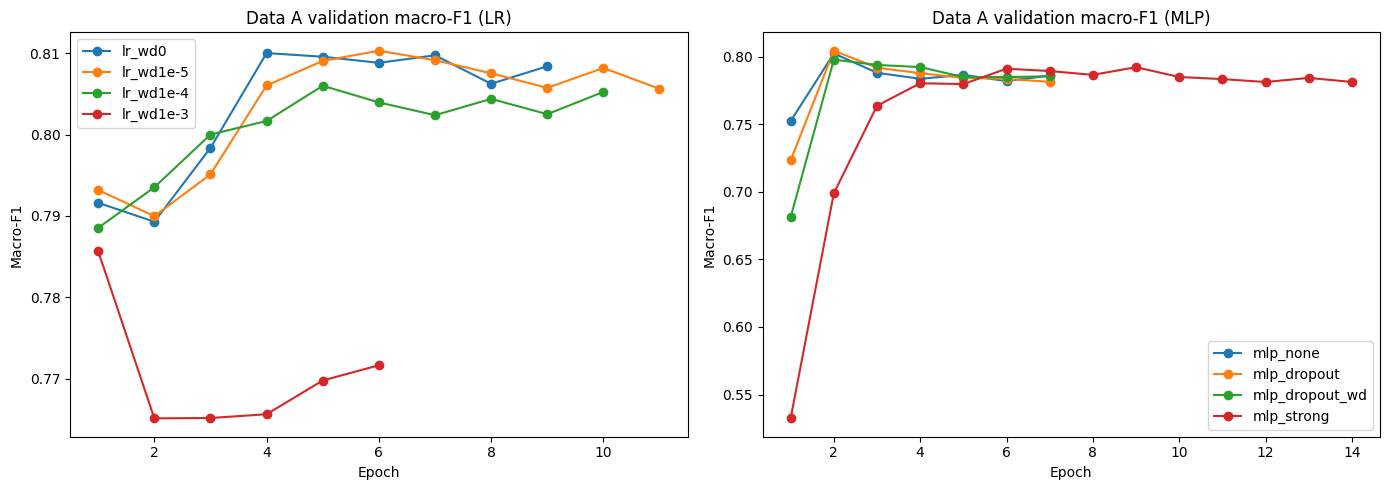

In [9]:
# Validation macro-F1 per epoch for every setting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, kind in zip(axes, ["lr", "mlp"]):
    for name, (k, _) in ALL_SETTINGS.items():
        if k == kind:
            h = pd.DataFrame(histories[name])
            ax.plot(h["epoch"], h["val_macro_f1"], marker="o", label=name)
    ax.set_title(f"Data A validation macro-F1 ({kind.upper()})")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Macro-F1")
    ax.legend()
plt.tight_layout()
plt.savefig("results/part3/validation_curves.png", dpi=150)
plt.show()

### Step 2: Select one setting per model (validation only)
The selection is saved before any test set is touched.

In [10]:
best_lr = sweep_df[sweep_df.model == "LR"].sort_values("val_macro_f1", ascending=False).iloc[0]["setting"]
best_mlp = sweep_df[sweep_df.model == "MLP"].sort_values("val_macro_f1", ascending=False).iloc[0]["setting"]

selection = {
    "seed": SEED,
    "criterion": "highest Data A validation macro-F1",
    "selected_lr": best_lr, "lr_config": ALL_SETTINGS[best_lr][1], "lr_epochs": best_epochs[best_lr],
    "selected_mlp": best_mlp, "mlp_config": ALL_SETTINGS[best_mlp][1], "mlp_epochs": best_epochs[best_mlp],
}
with open("results/part3/selection.json", "w") as f:
    json.dump(selection, f, indent=2)
print(json.dumps(selection, indent=2))

{
  "seed": 0,
  "criterion": "highest Data A validation macro-F1",
  "selected_lr": "lr_wd1e-5",
  "lr_config": {
    "lr": 0.01,
    "weight_decay": 1e-05
  },
  "lr_epochs": 6,
  "selected_mlp": "mlp_dropout",
  "mlp_config": {
    "lr": 0.001,
    "weight_decay": 0.0,
    "dropout": [
      0.2,
      0.3
    ]
  },
  "mlp_epochs": 2
}


### Step 3: Refit on all of Data A train, evaluate on Data A test and Data B test
The refit trains for the best epoch count found on validation, since there is no validation set left to early-stop on.

In [11]:
vec_full = TfidfVectorizer()  # refit on ALL of dataset_a_train.csv
X_a_full = vec_full.fit_transform(article_text(SOURCE_A_TRAIN))
y_a_full = SOURCE_A_TRAIN["Label"].to_numpy()
X_a_test = vec_full.transform(article_text(SOURCE_A_TEST))
y_a_test = SOURCE_A_TEST["Label"].to_numpy()
X_b_test = vec_full.transform(article_text(SOURCE_B_TEST))  # transform only, never fit
y_b_test = SOURCE_B_TEST["Label"].to_numpy()
print("vocab size:", len(vec_full.vocabulary_))

FINAL_MODELS, final_results = {}, {}
for tag, name in [("lr", best_lr), ("mlp", best_mlp)]:
    kind, setting = ALL_SETTINGS[name]
    model, _, _ = train_model(kind, setting, X_a_full, y_a_full, epochs=best_epochs[name])
    FINAL_MODELS[tag] = model
    torch.save(model.state_dict(), f"models/part3_final_{tag}.pt")
    final_results[tag] = {
        "setting": name, "config": setting, "epochs": best_epochs[name], "seed": SEED,
        "representation": "unigram TF-IDF, title + description",
        "train_data": "all of dataset_a_train.csv", "train_size": len(SOURCE_A_TRAIN),
        "A_test": evaluate(y_a_test, predict(model, X_a_test)),
        "B_test": evaluate(y_b_test, predict(model, X_b_test)),
    }
joblib.dump(vec_full, "models/part3_vectorizer.joblib")

with open("results/part3/final_results.json", "w") as f:
    json.dump(final_results, f, indent=2)

summary = pd.DataFrame([{
    "model": tag.upper(), "setting": r["setting"],
    "A_test_acc": r["A_test"]["accuracy"], "A_test_macro_f1": r["A_test"]["macro_f1"],
    "B_test_acc": r["B_test"]["accuracy"], "B_test_macro_f1": r["B_test"]["macro_f1"],
} for tag, r in final_results.items()])
display(summary)

vocab size: 19834


,model,setting,A_test_acc,A_test_macro_f1,B_test_acc,B_test_macro_f1
0,LR,lr_wd1e-5,0.5648,0.564727,0.780225,0.788776
1,MLP,mlp_dropout,0.5784,0.574852,0.792360,0.794088


,model,label,class,A_precision,A_recall,A_f1,B_precision,B_recall,B_f1,f1_drop
0,LR,1,Politics,0.383,0.374,0.379,0.938,0.542,0.687,-0.308
1,LR,2,Sports,0.652,0.664,0.658,0.982,0.871,0.923,-0.265
2,LR,3,Business,0.612,0.564,0.587,0.527,0.990,0.688,-0.101
3,LR,4,Technology,0.683,0.684,0.683,0.981,0.643,0.777,-0.094
4,LR,5,Entertainment,0.497,0.538,0.517,0.977,0.782,0.869,-0.352
5,MLP,1,Politics,0.404,0.372,0.388,0.874,0.468,0.609,-0.222
6,MLP,2,Sports,0.667,0.696,0.681,0.983,0.896,0.938,-0.257
7,MLP,3,Business,0.612,0.552,0.580,0.556,0.986,0.711,-0.131
8,MLP,4,Technology,0.662,0.748,0.702,0.931,0.746,0.828,-0.126
9,MLP,5,Entertainment,0.522,0.524,0.523,0.990,0.798,0.884,-0.361


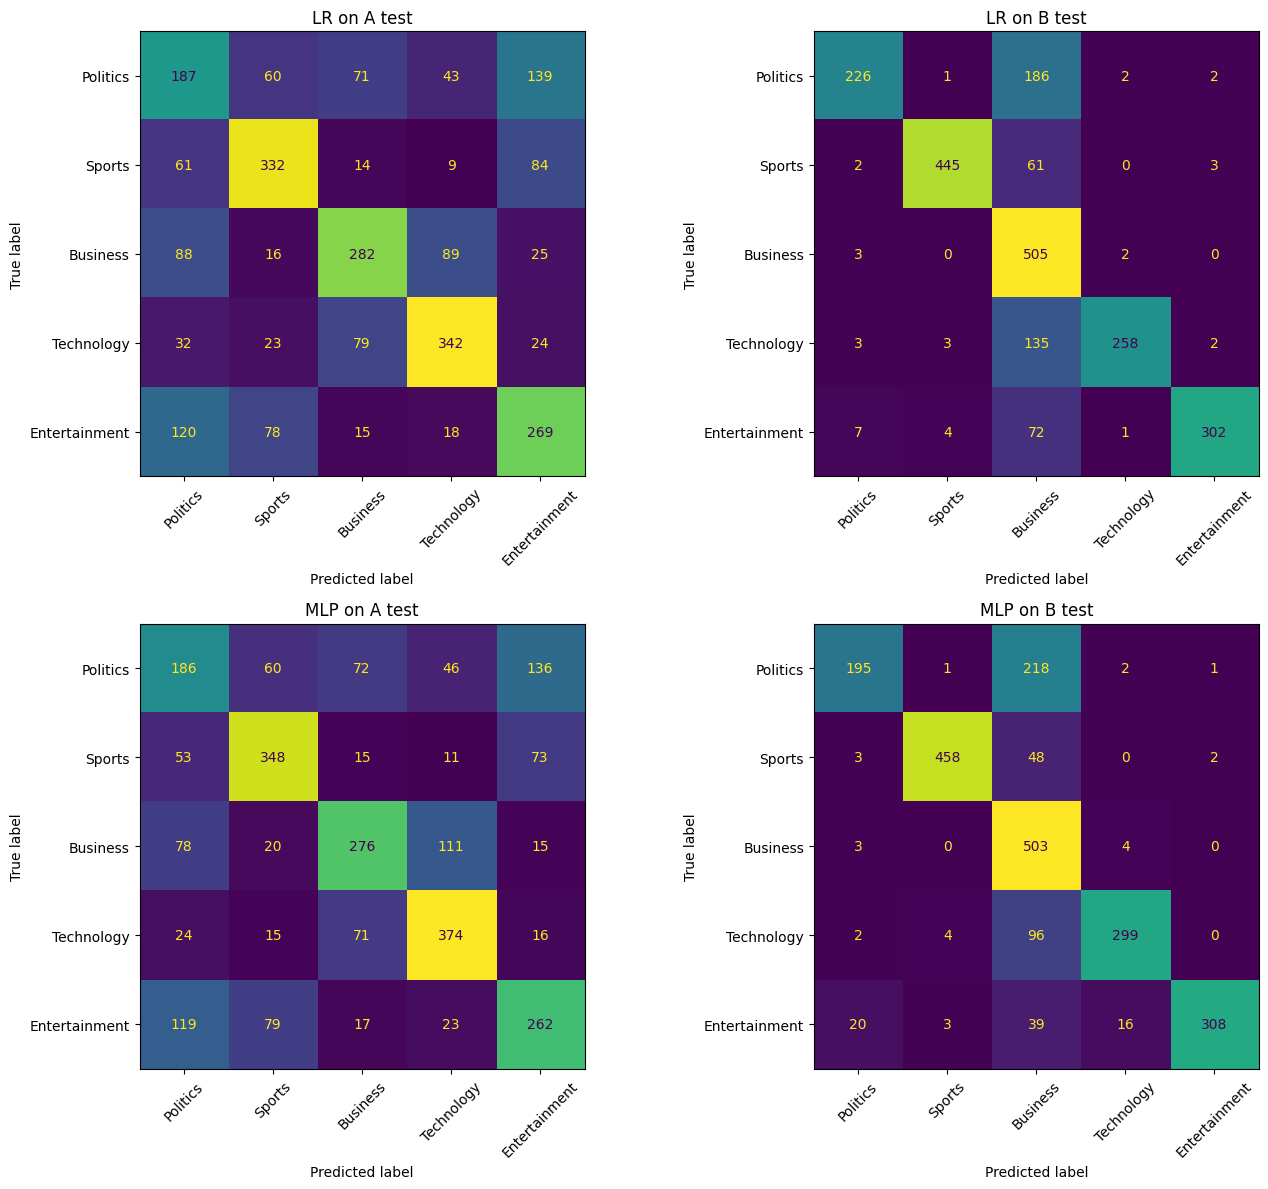

In [12]:
# Per-class precision / recall / F1, Data A vs Data B
rows = []
for tag, r in final_results.items():
    for lab in CLASS_IDS:
        a, b = r["A_test"]["per_class"][str(lab)], r["B_test"]["per_class"][str(lab)]
        rows.append({"model": tag.upper(), "label": lab, "class": LABELS.loc[lab, "Set A"],
                     "A_precision": a["precision"], "A_recall": a["recall"], "A_f1": a["f1-score"],
                     "B_precision": b["precision"], "B_recall": b["recall"], "B_f1": b["f1-score"],
                     "f1_drop": a["f1-score"] - b["f1-score"]})
per_class = pd.DataFrame(rows)
per_class.to_csv("results/part3/per_class_A_vs_B.csv", index=False)
display(per_class.round(3))

# Confusion matrices
class_names = list(LABELS["Set A"])
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for i, tag in enumerate(["lr", "mlp"]):
    for j, ds in enumerate(["A_test", "B_test"]):
        cm = np.array(final_results[tag][ds]["confusion_matrix"])
        ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
            ax=axes[i, j], colorbar=False, xticks_rotation=45)
        axes[i, j].set_title(f"{tag.upper()} on {ds.replace('_', ' ')}")
plt.tight_layout()
plt.savefig("results/part3/confusion_matrices.png", dpi=150)
plt.show()

### Step 4 (post hoc): every setting on the test sets
Reported for analysis only. These numbers were not used to pick the final models.

In [13]:
posthoc = []
for name, (kind, setting) in ALL_SETTINGS.items():
    model, _, _ = train_model(kind, setting, X_a_full, y_a_full, epochs=best_epochs[name])
    fa = evaluate(y_a_test, predict(model, X_a_test))["macro_f1"]
    fb = evaluate(y_b_test, predict(model, X_b_test))["macro_f1"]
    posthoc.append({"setting": name, "model": kind.upper(),
                    "A_test_macro_f1": fa, "B_test_macro_f1": fb, "A_minus_B": fa - fb})
posthoc_df = pd.DataFrame(posthoc)
posthoc_df.to_csv("results/part3/posthoc_all_settings.csv", index=False)
display(posthoc_df.round(4))

,setting,model,A_test_macro_f1,B_test_macro_f1,A_minus_B
0,lr_wd0,LR,0.5599,0.7864,-0.2266
1,lr_wd1e-5,LR,0.5647,0.7888,-0.2240
2,lr_wd1e-4,LR,0.5626,0.7597,-0.1971
3,lr_wd1e-3,LR,0.5472,0.5494,-0.0021
4,mlp_none,MLP,0.5749,0.8230,-0.2482
5,mlp_dropout,MLP,0.5749,0.7941,-0.2192
6,mlp_dropout_wd,MLP,0.5723,0.7797,-0.2075
7,mlp_strong,MLP,0.5519,0.7357,-0.1838


### Step 5: Transfer diagnostics (for the A vs B discussion)
Class balance, text length in words, and out-of-vocabulary rate relative to the Data A vocabulary.

In [14]:
def word_count(s):
    return s.fillna("").astype(str).str.split().str.len()

analyzer, vocab = vec_full.build_analyzer(), vec_full.vocabulary_
diag_rows = []
for dname, df in [("A_train", SOURCE_A_TRAIN), ("A_test", SOURCE_A_TEST), ("B_test", SOURCE_B_TEST)]:
    toks = [t for doc in article_text(df) for t in analyzer(doc)]
    props = df["Label"].value_counts(normalize=True).sort_index()
    diag_rows.append({
        "dataset": dname, "n": len(df),
        **{f"pct_label_{k}": round(100 * props.get(k, 0), 1) for k in CLASS_IDS},
        "title_words_median": word_count(df["Title"]).median(),
        "desc_words_median": word_count(df["Description"]).median(),
        "oov_rate_vs_A_vocab": round(float(np.mean([t not in vocab for t in toks])), 4),
    })
diag_df = pd.DataFrame(diag_rows)
diag_df.to_csv("results/part3/transfer_diagnostics.csv", index=False)
display(diag_df)

,dataset,n,pct_label_1,pct_label_2,pct_label_3,pct_label_4,pct_label_5,title_words_median,desc_words_median,oov_rate_vs_A_vocab
0,A_train,7500,20.0,20.0,20.0,20.0,20.0,10.0,17.0,0.0000
1,A_test,2500,20.0,20.0,20.0,20.0,20.0,11.0,15.0,0.0528
2,B_test,2225,18.7,23.0,22.9,18.0,17.3,5.0,326.0,0.0736


### Frozen models for Part 4
`FINAL_MODELS["lr"]`, `FINAL_MODELS["mlp"]`, and `vec_full` stay in memory. They are also saved to `models/`. To reload them in a fresh session:

```python
vec_full = joblib.load("models/part3_vectorizer.joblib")
n_feat = len(vec_full.vocabulary_)
FINAL_MODELS = {}
for tag in ["lr", "mlp"]:
    kind, setting = ALL_SETTINGS[selection[f"selected_{tag}"]]
    m = build_model(kind, n_feat, setting.get("dropout", (0.0, 0.0))).to(DEVICE)
    m.load_state_dict(torch.load(f"models/part3_final_{tag}.pt", map_location=DEVICE))
    FINAL_MODELS[tag] = m.eval()
```

### Duplicate check
Checking whether duplicate articles explain the gap between validation and A test scores.

In [15]:
dup_rows = SOURCE_A_TRAIN.duplicated().sum()
dup_text = article_text(SOURCE_A_TRAIN).duplicated().sum()
train_text = set(article_text(p3_train))
val_overlap = article_text(p3_val).isin(train_text).sum()
test_overlap = article_text(SOURCE_A_TEST).isin(set(article_text(SOURCE_A_TRAIN))).sum()
print("duplicate rows in A train:", dup_rows)
print("duplicate texts in A train:", dup_text)
print("val articles also in train split:", val_overlap, "/", len(p3_val))
print("A test articles also in A train:", test_overlap, "/", len(SOURCE_A_TEST))

duplicate rows in A train: 47
duplicate texts in A train: 47
val articles also in train split: 15 / 1500
A test articles also in A train: 0 / 2500


## Part 5: Adding Limited Data C Training Examples
Uses the final settings chosen in Part 3 (no Data C results were used to pick them). Only `dataset_c_train.csv` is ever added to training. `dataset_c_test.csv` is evaluation only.

In [16]:
SOURCE_C_TRAIN = pd.read_csv("./data/dataset_c_train.csv")
SOURCE_C_TEST = pd.read_csv("./data/dataset_c_test.csv")
print("C train", SOURCE_C_TRAIN.shape, " C test", SOURCE_C_TEST.shape)
print("\nC train class counts:")
print(SOURCE_C_TRAIN["Label"].value_counts().sort_index())

C train (6000, 3)  C test (2000, 3)

C train class counts:
Label
1    1500
2    1500
3    1500
4    1500
Name: count, dtype: int64


### Final settings from Part 3
Loaded from `results/part3/selection.json`. Each model is refit for the same number of epochs Part 3 used.

In [17]:
os.makedirs("results/part5", exist_ok=True)

try:
    with open("results/part3/selection.json") as f:
        selection = json.load(f)
except FileNotFoundError:
    # Values from the Part 3 run, in case the file is missing
    selection = {"selected_lr": "lr_wd1e-5", "lr_config": {"lr": 0.01, "weight_decay": 1e-05}, "lr_epochs": 6,
                 "selected_mlp": "mlp_dropout",
                 "mlp_config": {"lr": 0.001, "weight_decay": 0.0, "dropout": [0.2, 0.3]}, "mlp_epochs": 2}

FINAL = {
    "lr":  {"kind": "lr", "name": selection["selected_lr"], "setting": selection["lr_config"],
            "epochs": selection["lr_epochs"]},
    "mlp": {"kind": "mlp", "name": selection["selected_mlp"],
            "setting": {**selection["mlp_config"], "dropout": tuple(selection["mlp_config"]["dropout"])},
            "epochs": selection["mlp_epochs"]},
}
for tag, cfg in FINAL.items():
    print(tag, cfg)

lr {'kind': 'lr', 'name': 'lr_wd1e-5', 'setting': {'lr': 0.01, 'weight_decay': 1e-05}, 'epochs': 6}
mlp {'kind': 'mlp', 'name': 'mlp_dropout', 'setting': {'lr': 0.001, 'weight_decay': 0.0, 'dropout': (0.2, 0.3)}, 'epochs': 2}


### Sampling procedure
Each Data C class is shuffled once with a fixed seed. A sample takes the first *n* rows of each shuffled class, so every smaller sample is a subset of the larger ones. Budgets are split as evenly as possible across the strategy's labels.

In [18]:
BUDGETS = [50, 150, 600, 1500]
STRATEGIES = {
    "label1_only": [1],           # Data C World examples only
    "shared_only": [2, 3, 4],     # Sports, Business, Technology
    "balanced":    [1, 2, 3, 4],  # roughly equal from all four
}
SAMPLE_SEED = 0
C_LABELS = [1, 2, 3, 4]

C_POOLS = {lab: SOURCE_C_TRAIN[SOURCE_C_TRAIN["Label"] == lab].sample(frac=1, random_state=SAMPLE_SEED)
           for lab in C_LABELS}


def per_class_counts(budget, labels):
    base, extra = divmod(budget, len(labels))
    return {lab: base + (1 if i < extra else 0) for i, lab in enumerate(labels)}


def sample_c(budget, strategy):
    counts = per_class_counts(budget, STRATEGIES[strategy])
    parts = []
    for lab, n in counts.items():
        if n > len(C_POOLS[lab]):
            raise ValueError(f"Need {n} examples of C label {lab}, only {len(C_POOLS[lab])} available")
        parts.append(C_POOLS[lab].iloc[:n])
    return pd.concat(parts), counts


for s in STRATEGIES:
    print(s, {b: per_class_counts(b, STRATEGIES[s]) for b in BUDGETS})

label1_only {50: {1: 50}, 150: {1: 150}, 600: {1: 600}, 1500: {1: 1500}}
shared_only {50: {2: 17, 3: 17, 4: 16}, 150: {2: 50, 3: 50, 4: 50}, 600: {2: 200, 3: 200, 4: 200}, 1500: {2: 500, 3: 500, 4: 500}}
balanced {50: {1: 13, 2: 13, 3: 12, 4: 12}, 150: {1: 38, 2: 38, 3: 37, 4: 37}, 600: {1: 150, 2: 150, 3: 150, 4: 150}, 1500: {1: 375, 2: 375, 3: 375, 4: 375}}


### Metrics
- C label-1 recall and F1
- C overall macro-F1 over labels 1-4
- C strict macro-F1 over labels 2-4, computed on the full C test set (World articles predicted as Sports/Business/Tech count as false positives)
- C shared-only macro-F1 over labels 2-4, computed only on C test articles whose true label is 2-4 (same as Part 4)
- % of C test predicted as label 5 (a class C does not have)
- A test and B test macro-F1 (retained performance)

In [19]:
TXT_A_TEST, TXT_B_TEST, TXT_C_TEST = (article_text(SOURCE_A_TEST), article_text(SOURCE_B_TEST),
                                      article_text(SOURCE_C_TEST))
y_a_test = SOURCE_A_TEST["Label"].to_numpy()
y_b_test = SOURCE_B_TEST["Label"].to_numpy()
y_c_test = SOURCE_C_TEST["Label"].to_numpy()
SHARED_MASK = np.isin(y_c_test, [2, 3, 4])


def part5_metrics(model, vec):
    pc = predict(model, vec.transform(TXT_C_TEST))
    pa = predict(model, vec.transform(TXT_A_TEST))
    pb = predict(model, vec.transform(TXT_B_TEST))
    rep = classification_report(y_c_test, pc, labels=C_LABELS, output_dict=True, zero_division=0)
    f1 = lambda yt, yp, labs: float(f1_score(yt, yp, labels=labs, average="macro", zero_division=0))
    metrics = {
        "C_label1_recall": rep["1"]["recall"],
        "C_label1_f1": rep["1"]["f1-score"],
        "C_macro_f1_1to4": f1(y_c_test, pc, C_LABELS),
        "C_strict_macro_f1_2to4": f1(y_c_test, pc, [2, 3, 4]),
        "C_shared_only_macro_f1_2to4": f1(y_c_test[SHARED_MASK], pc[SHARED_MASK], [2, 3, 4]),
        "C_pct_pred_label5": float(100 * np.mean(pc == 5)),
        "A_test_macro_f1": f1(y_a_test, pa, CLASS_IDS),
        "B_test_macro_f1": f1(y_b_test, pb, CLASS_IDS),
    }
    cm = confusion_matrix(y_c_test, pc, labels=CLASS_IDS).tolist()
    return metrics, cm

### Run every condition
Budget 0 is the frozen Part 3 model (run once per model). Every other condition refits TF-IDF and the classifier on Data A train plus the sampled Data C examples. 2 models x 3 strategies x 4 budgets = 24 runs.

In [20]:
rows, conf_mats = [], {}

for tag, cfg in FINAL.items():
    # ---- budget 0: the Part 3 model, loaded from disk if available
    try:
        vec0 = joblib.load("models/part3_vectorizer.joblib")
        model0 = build_model(cfg["kind"], len(vec0.vocabulary_), cfg["setting"].get("dropout", (0.0, 0.0))).to(DEVICE)
        model0.load_state_dict(torch.load(f"models/part3_final_{tag}.pt", map_location=DEVICE))
        src = "loaded Part 3 model"
    except FileNotFoundError:
        vec0 = TfidfVectorizer()
        X0 = vec0.fit_transform(article_text(SOURCE_A_TRAIN))
        model0, _, _ = train_model(cfg["kind"], cfg["setting"], X0, SOURCE_A_TRAIN["Label"].to_numpy(),
                                   epochs=cfg["epochs"])
        src = "retrained Part 3 config"
    met, cm = part5_metrics(model0, vec0)
    rows.append({"model": tag.upper(), "strategy": "baseline", "budget": 0, "c_counts": "{}",
                 "train_size": len(SOURCE_A_TRAIN), "vocab_size": len(vec0.vocabulary_), **met})
    conf_mats[f"{tag}_baseline_0"] = cm
    print(f"{tag.upper()} baseline ({src}): C macro-F1={met['C_macro_f1_1to4']:.4f}  C label-1 F1={met['C_label1_f1']:.4f}")

    # ---- nonzero budgets
    for strategy in STRATEGIES:
        for budget in BUDGETS:
            c_sample, counts = sample_c(budget, strategy)
            train_df = pd.concat([SOURCE_A_TRAIN, c_sample], ignore_index=True)
            vec = TfidfVectorizer()  # refit on A train + selected C examples
            X = vec.fit_transform(article_text(train_df))
            y = train_df["Label"].to_numpy()  # C World examples keep label 1
            model, _, _ = train_model(cfg["kind"], cfg["setting"], X, y, epochs=cfg["epochs"])
            met, cm = part5_metrics(model, vec)
            rows.append({"model": tag.upper(), "strategy": strategy, "budget": budget,
                         "c_counts": str(counts), "train_size": len(train_df),
                         "vocab_size": len(vec.vocabulary_), **met})
            conf_mats[f"{tag}_{strategy}_{budget}"] = cm
            print(f"{tag.upper()} {strategy:12s} {budget:5d}  C macro-F1={met['C_macro_f1_1to4']:.4f}  "
                  f"C label-1 F1={met['C_label1_f1']:.4f}  A={met['A_test_macro_f1']:.4f}  B={met['B_test_macro_f1']:.4f}")

results_df = pd.DataFrame(rows)
results_df.to_csv("results/part5/all_conditions.csv", index=False)
with open("results/part5/confusion_matrices.json", "w") as f:
    json.dump(conf_mats, f)
with open("results/part5/config.json", "w") as f:
    json.dump({"seed": SEED, "sample_seed": SAMPLE_SEED, "budgets": BUDGETS, "strategies": STRATEGIES,
               "final_settings": {k: {**v, "setting": dict(v["setting"])} for k, v in FINAL.items()},
               "representation": "unigram TF-IDF, title + description"}, f, indent=2, default=str)

LR baseline (loaded Part 3 model): C macro-F1=0.5608  C label-1 F1=0.4983
LR label1_only     50  C macro-F1=0.5657  C label-1 F1=0.5406  A=0.5622  B=0.8006
LR label1_only    150  C macro-F1=0.5609  C label-1 F1=0.5512  A=0.5594  B=0.8059
LR label1_only    600  C macro-F1=0.5450  C label-1 F1=0.5535  A=0.5514  B=0.8183
LR label1_only   1500  C macro-F1=0.5299  C label-1 F1=0.5403  A=0.5494  B=0.7966
LR shared_only     50  C macro-F1=0.5553  C label-1 F1=0.4904  A=0.5657  B=0.7971
LR shared_only    150  C macro-F1=0.5532  C label-1 F1=0.4631  A=0.5674  B=0.8029
LR shared_only    600  C macro-F1=0.5681  C label-1 F1=0.4203  A=0.5693  B=0.8112
LR shared_only   1500  C macro-F1=0.5609  C label-1 F1=0.3628  A=0.5754  B=0.8063
LR balanced        50  C macro-F1=0.5584  C label-1 F1=0.5174  A=0.5647  B=0.7990
LR balanced       150  C macro-F1=0.5788  C label-1 F1=0.5482  A=0.5657  B=0.8045
LR balanced       600  C macro-F1=0.6108  C label-1 F1=0.5812  A=0.5708  B=0.8302
LR balanced      1500  C

### Results tables

In [21]:
METRIC_COLS = ["C_label1_recall", "C_label1_f1", "C_macro_f1_1to4", "C_strict_macro_f1_2to4",
               "C_shared_only_macro_f1_2to4", "C_pct_pred_label5", "A_test_macro_f1", "B_test_macro_f1"]
for tag in ["LR", "MLP"]:
    print(f"\n===== {tag} =====")
    display(results_df[results_df.model == tag][["strategy", "budget", "train_size"] + METRIC_COLS]
            .round(4).reset_index(drop=True))


===== LR =====


,strategy,budget,train_size,C_label1_recall,C_label1_f1,C_macro_f1_1to4,C_strict_macro_f1_2to4,C_shared_only_macro_f1_2to4,C_pct_pred_label5,A_test_macro_f1,B_test_macro_f1
0,baseline,0,7500,0.430,0.4983,0.5608,0.5816,0.6286,6.95,0.5647,0.7888
1,label1_only,50,7550,0.552,0.5406,0.5657,0.5740,0.6122,5.20,0.5622,0.8006
2,label1_only,150,7650,0.630,0.5512,0.5609,0.5641,0.5961,4.65,0.5594,0.8059
3,label1_only,600,8100,0.714,0.5535,0.5450,0.5422,0.5672,3.75,0.5514,0.8183
4,label1_only,1500,9000,0.758,0.5403,0.5299,0.5264,0.5481,3.40,0.5494,0.7966
5,shared_only,50,7550,0.408,0.4904,0.5553,0.5770,0.6276,5.30,0.5657,0.7971
6,shared_only,150,7650,0.370,0.4631,0.5532,0.5832,0.6366,4.90,0.5674,0.8029
7,shared_only,600,8100,0.306,0.4203,0.5681,0.6174,0.6818,4.05,0.5693,0.8112
8,shared_only,1500,9000,0.246,0.3628,0.5609,0.6269,0.7004,2.65,0.5754,0.8063
9,balanced,50,7550,0.460,0.5174,0.5584,0.5721,0.6177,5.50,0.5647,0.7990



===== MLP =====


,strategy,budget,train_size,C_label1_recall,C_label1_f1,C_macro_f1_1to4,C_strict_macro_f1_2to4,C_shared_only_macro_f1_2to4,C_pct_pred_label5,A_test_macro_f1,B_test_macro_f1
0,baseline,0,7500,0.392,0.4763,0.5597,0.5875,0.6378,5.50,0.5749,0.7941
1,label1_only,50,7550,0.556,0.5409,0.5697,0.5793,0.6198,4.50,0.5704,0.8378
2,label1_only,150,7650,0.584,0.5438,0.5429,0.5427,0.5774,4.15,0.5777,0.7690
3,label1_only,600,8100,0.716,0.5585,0.5527,0.5508,0.5766,3.85,0.5614,0.8402
4,label1_only,1500,9000,0.742,0.5592,0.5173,0.5033,0.5260,4.00,0.5654,0.7879
5,shared_only,50,7550,0.424,0.4988,0.5776,0.6039,0.6553,5.20,0.5696,0.8254
6,shared_only,150,7650,0.354,0.4515,0.5571,0.5923,0.6458,6.15,0.5648,0.8093
7,shared_only,600,8100,0.354,0.4597,0.5764,0.6153,0.6747,3.95,0.5674,0.8330
8,shared_only,1500,9000,0.252,0.3679,0.5688,0.6358,0.7055,3.50,0.5723,0.8180
9,balanced,50,7550,0.430,0.5035,0.5651,0.5856,0.6351,4.45,0.5838,0.8290


### Plots: added Data C examples vs C label-1 F1 and C macro-F1

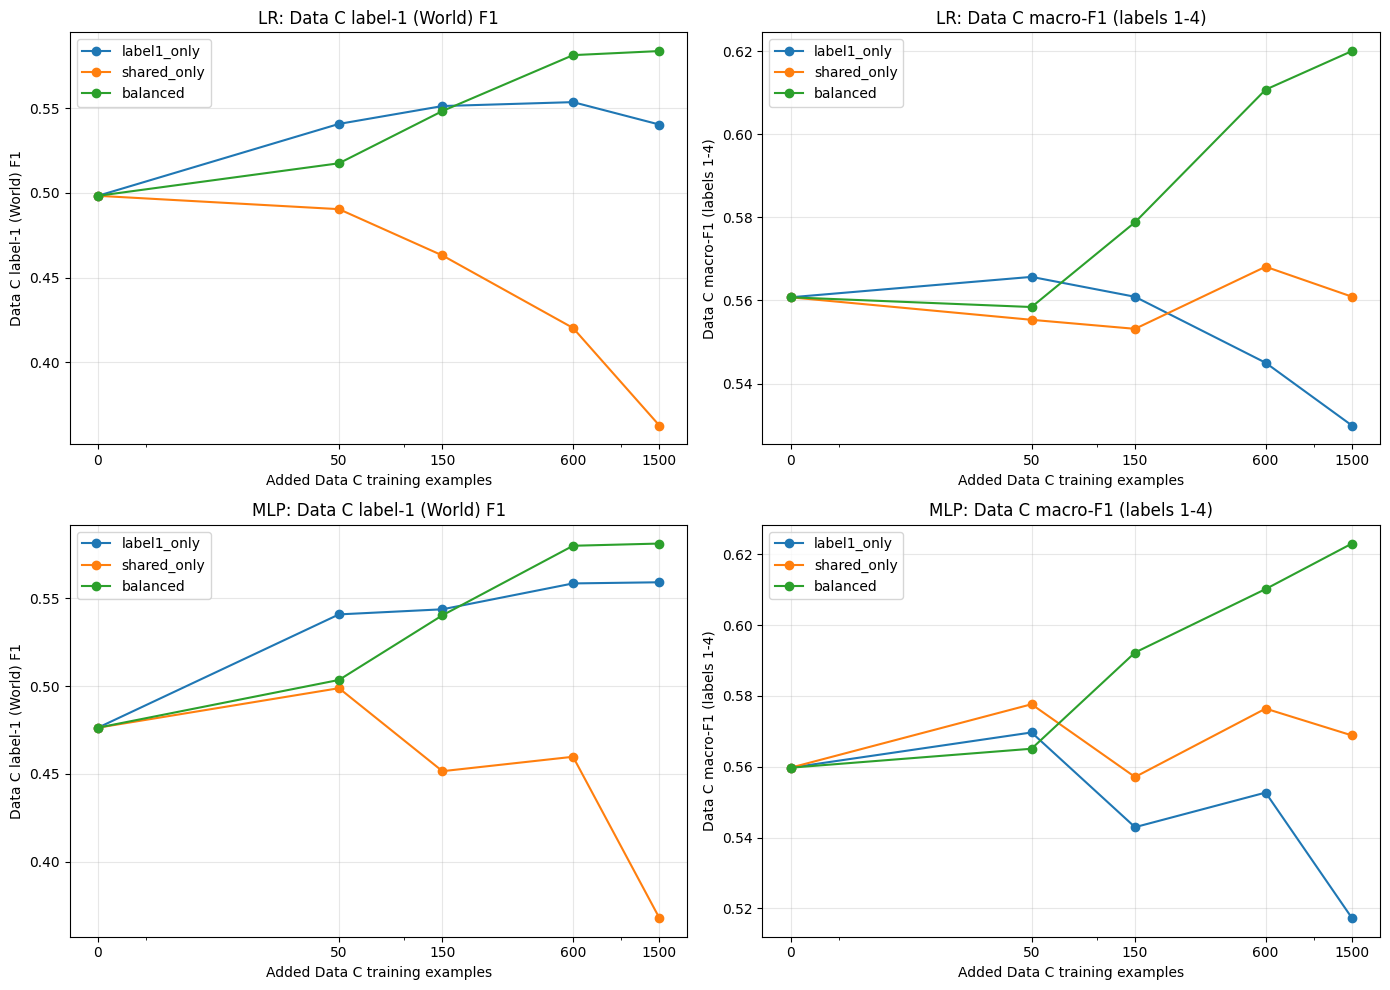

In [22]:
TICKS = [0] + BUDGETS
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for i, tag in enumerate(["LR", "MLP"]):
    d = results_df[results_df.model == tag]
    base = d[d.budget == 0].iloc[0]
    for j, (metric, label) in enumerate([("C_label1_f1", "Data C label-1 (World) F1"),
                                         ("C_macro_f1_1to4", "Data C macro-F1 (labels 1-4)")]):
        ax = axes[i, j]
        for s in STRATEGIES:
            ds = d[d.strategy == s].sort_values("budget")
            ax.plot([0] + ds.budget.tolist(), [base[metric]] + ds[metric].tolist(), marker="o", label=s)
        ax.set_xscale("symlog", linthresh=50)
        ax.set_xticks(TICKS)
        ax.set_xticklabels(TICKS)
        ax.set_xlabel("Added Data C training examples")
        ax.set_ylabel(label)
        ax.set_title(f"{tag}: {label}")
        ax.grid(alpha=0.3)
        ax.legend()
plt.tight_layout()
plt.savefig("results/part5/budget_curves.png", dpi=150)
plt.show()

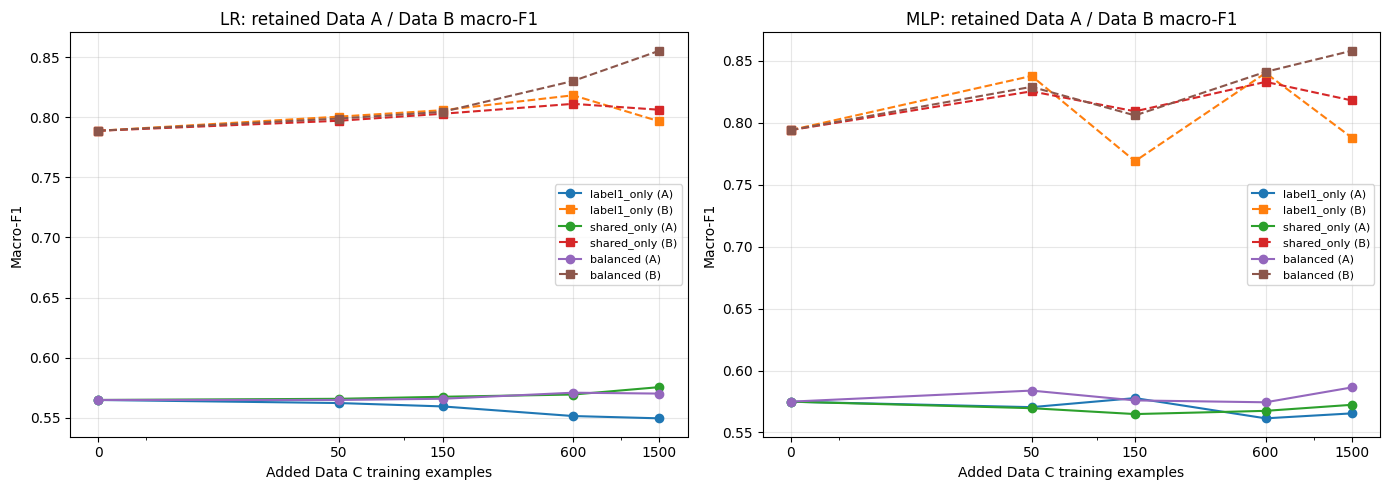

In [23]:
# Retained performance on Data A and Data B
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, tag in enumerate(["LR", "MLP"]):
    d = results_df[results_df.model == tag]
    base = d[d.budget == 0].iloc[0]
    ax = axes[i]
    for s in STRATEGIES:
        ds = d[d.strategy == s].sort_values("budget")
        x = [0] + ds.budget.tolist()
        ax.plot(x, [base["A_test_macro_f1"]] + ds["A_test_macro_f1"].tolist(), marker="o", label=f"{s} (A)")
        ax.plot(x, [base["B_test_macro_f1"]] + ds["B_test_macro_f1"].tolist(), marker="s", linestyle="--", label=f"{s} (B)")
    ax.set_xscale("symlog", linthresh=50)
    ax.set_xticks(TICKS)
    ax.set_xticklabels(TICKS)
    ax.set_xlabel("Added Data C training examples")
    ax.set_ylabel("Macro-F1")
    ax.set_title(f"{tag}: retained Data A / Data B macro-F1")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("results/part5/retention_curves.png", dpi=150)
plt.show()

### Requirement check
Every adapted Part 5 model needs at least 40% macro-F1 on the Data C test set (labels 1-4).

In [24]:
adapted = results_df[results_df.budget > 0]
check = adapted[["model", "strategy", "budget", "C_macro_f1_1to4"]].copy()
check["passes_40pct"] = check["C_macro_f1_1to4"] >= 0.40
display(check.round(4))
print("All adapted models pass:", bool(check["passes_40pct"].all()))

,model,strategy,budget,C_macro_f1_1to4,passes_40pct
1,LR,label1_only,50,0.5657,True
2,LR,label1_only,150,0.5609,True
3,LR,label1_only,600,0.5450,True
4,LR,label1_only,1500,0.5299,True
5,LR,shared_only,50,0.5553,True
6,LR,shared_only,150,0.5532,True
7,LR,shared_only,600,0.5681,True
8,LR,shared_only,1500,0.5609,True
9,LR,balanced,50,0.5584,True
10,LR,balanced,150,0.5788,True


All adapted models pass: True


## Selected Component: Unigram + Bigram TF-IDF
**Variation:** `TfidfVectorizer(ngram_range=(1, 2), min_df=2)`. Features are single words plus two-word phrases. `min_df=2` drops any term that appears in only one training document, which keeps the much larger bigram vocabulary manageable.

**Why it might help:** phrases like "prime minister", "stock market", or "world cup" carry topic meaning that the separate words do not. That could sharpen class boundaries in domain and help separate World from Business and Technology in Data C.

**Why it might hurt:** many bigrams are specific to one source's writing style or headline habits, so they can fit Data A closely and transfer worse to Data B and Data C. The feature space also grows a lot, which makes overfitting easier for the MLP.

Everything else is identical to the required component: same split, seeds, regularization settings, selection rule, refit procedure, sampling, and metrics.

In [25]:
EXT_REPR = "unigram+bigram TF-IDF (ngram_range=(1,2), min_df=2), title + description"


def make_ext_vec():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2)


os.makedirs("results/extension", exist_ok=True)

### Extension, Part 3 redo: sweep on the same Data A validation split

In [26]:
ext_vec_split = make_ext_vec()  # fit on the same 80% training split as Part 3
Xe_tr = ext_vec_split.fit_transform(article_text(p3_train))
Xe_val = ext_vec_split.transform(article_text(p3_val))
print("features  baseline:", X_tr.shape[1], "  extension:", Xe_tr.shape[1])

ext_sweep_rows, ext_best_epochs, ext_histories = [], {}, {}
for name, (kind, setting) in ALL_SETTINGS.items():
    model, best_epoch, hist = train_model(kind, setting, Xe_tr, y_tr, Xe_val, y_val)
    m = evaluate(y_val, predict(model, Xe_val))
    ext_best_epochs[name], ext_histories[name] = best_epoch, hist
    ext_sweep_rows.append({
        "setting": name, "model": kind.upper(), "lr": setting["lr"],
        "weight_decay": setting["weight_decay"], "dropout": str(setting.get("dropout", "n/a")),
        "best_epoch": best_epoch, "val_accuracy": m["accuracy"], "val_macro_f1": m["macro_f1"],
    })
    print(f"{name:16s} best_epoch={best_epoch:2d}  val acc={m['accuracy']:.4f}  val macro-F1={m['macro_f1']:.4f}")

ext_sweep_df = pd.DataFrame(ext_sweep_rows)
ext_sweep_df.to_csv("results/extension/validation_sweep.csv", index=False)
display(ext_sweep_df)

features  baseline: 17857   extension: 25465
lr_wd0           best_epoch= 4  val acc=0.7967  val macro-F1=0.7968
lr_wd1e-5        best_epoch=11  val acc=0.8040  val macro-F1=0.8043
lr_wd1e-4        best_epoch= 5  val acc=0.7993  val macro-F1=0.8000
lr_wd1e-3        best_epoch= 6  val acc=0.7713  val macro-F1=0.7725
mlp_none         best_epoch= 2  val acc=0.8080  val macro-F1=0.8085
mlp_dropout      best_epoch= 8  val acc=0.8120  val macro-F1=0.8117
mlp_dropout_wd   best_epoch= 6  val acc=0.8060  val macro-F1=0.8062
mlp_strong       best_epoch= 5  val acc=0.7580  val macro-F1=0.7587


,setting,model,lr,weight_decay,dropout,best_epoch,val_accuracy,val_macro_f1
0,lr_wd0,LR,0.010,0.00000,n/a,4,0.796667,0.796785
1,lr_wd1e-5,LR,0.010,0.00001,n/a,11,0.804000,0.804305
2,lr_wd1e-4,LR,0.010,0.00010,n/a,5,0.799333,0.800038
3,lr_wd1e-3,LR,0.010,0.00100,n/a,6,0.771333,0.772498
4,mlp_none,MLP,0.001,0.00000,"(0.0, 0.0)",2,0.808000,0.808541
5,mlp_dropout,MLP,0.001,0.00000,"(0.2, 0.3)",8,0.812000,0.811734
6,mlp_dropout_wd,MLP,0.001,0.00010,"(0.2, 0.3)",6,0.806000,0.806206
7,mlp_strong,MLP,0.001,0.00100,"(0.5, 0.5)",5,0.758000,0.758731


In [27]:
# Selection by Data A validation macro-F1 only, saved before any test evaluation
ext_best_lr = ext_sweep_df[ext_sweep_df.model == "LR"].sort_values("val_macro_f1", ascending=False).iloc[0]["setting"]
ext_best_mlp = ext_sweep_df[ext_sweep_df.model == "MLP"].sort_values("val_macro_f1", ascending=False).iloc[0]["setting"]

ext_selection = {
    "seed": SEED, "representation": EXT_REPR,
    "criterion": "highest Data A validation macro-F1",
    "selected_lr": ext_best_lr, "lr_config": ALL_SETTINGS[ext_best_lr][1], "lr_epochs": ext_best_epochs[ext_best_lr],
    "selected_mlp": ext_best_mlp, "mlp_config": ALL_SETTINGS[ext_best_mlp][1], "mlp_epochs": ext_best_epochs[ext_best_mlp],
}
with open("results/extension/selection.json", "w") as f:
    json.dump(ext_selection, f, indent=2)
print(json.dumps(ext_selection, indent=2))

{
  "seed": 0,
  "representation": "unigram+bigram TF-IDF (ngram_range=(1,2), min_df=2), title + description",
  "criterion": "highest Data A validation macro-F1",
  "selected_lr": "lr_wd1e-5",
  "lr_config": {
    "lr": 0.01,
    "weight_decay": 1e-05
  },
  "lr_epochs": 11,
  "selected_mlp": "mlp_dropout",
  "mlp_config": {
    "lr": 0.001,
    "weight_decay": 0.0,
    "dropout": [
      0.2,
      0.3
    ]
  },
  "mlp_epochs": 8
}


### Extension, Part 3 redo: refit on all of Data A train, evaluate on A test and B test

In [28]:
ext_vec_full = make_ext_vec()
Xe_a_full = ext_vec_full.fit_transform(article_text(SOURCE_A_TRAIN))
Xe_a_test = ext_vec_full.transform(article_text(SOURCE_A_TEST))
Xe_b_test = ext_vec_full.transform(article_text(SOURCE_B_TEST))  # transform only
print("vocab size  baseline:", len(vec_full.vocabulary_), "  extension:", len(ext_vec_full.vocabulary_))

EXT_FINAL_MODELS, ext_final_results = {}, {}
for tag, name in [("lr", ext_best_lr), ("mlp", ext_best_mlp)]:
    kind, setting = ALL_SETTINGS[name]
    model, _, _ = train_model(kind, setting, Xe_a_full, y_a_full, epochs=ext_best_epochs[name])
    EXT_FINAL_MODELS[tag] = model
    torch.save(model.state_dict(), f"models/ext_final_{tag}.pt")
    ext_final_results[tag] = {
        "setting": name, "config": setting, "epochs": ext_best_epochs[name], "seed": SEED,
        "representation": EXT_REPR, "train_data": "all of dataset_a_train.csv",
        "train_size": len(SOURCE_A_TRAIN), "vocab_size": len(ext_vec_full.vocabulary_),
        "A_test": evaluate(y_a_test, predict(model, Xe_a_test)),
        "B_test": evaluate(y_b_test, predict(model, Xe_b_test)),
    }
joblib.dump(ext_vec_full, "models/ext_vectorizer.joblib")
with open("results/extension/final_results.json", "w") as f:
    json.dump(ext_final_results, f, indent=2)

# Side-by-side with the required-component Part 3 models
cmp_rows = []
for tag in ["lr", "mlp"]:
    for rep, res, vsize in [("unigram (required)", final_results, len(vec_full.vocabulary_)),
                            ("uni+bigram (extension)", ext_final_results, len(ext_vec_full.vocabulary_))]:
        r = res[tag]
        cmp_rows.append({"model": tag.upper(), "representation": rep, "setting": r["setting"],
                         "epochs": r["epochs"], "features": vsize,
                         "A_test_acc": r["A_test"]["accuracy"], "A_test_macro_f1": r["A_test"]["macro_f1"],
                         "B_test_acc": r["B_test"]["accuracy"], "B_test_macro_f1": r["B_test"]["macro_f1"]})
p3_compare = pd.DataFrame(cmp_rows)
p3_compare.to_csv("results/extension/part3_comparison.csv", index=False)
display(p3_compare.round(4))
print("Extension Part 3 models pass 50% on A and B:",
      all(ext_final_results[t][d]["macro_f1"] >= 0.50 for t in ["lr", "mlp"] for d in ["A_test", "B_test"]))

vocab size  baseline: 19834   extension: 31068


,model,representation,setting,epochs,features,A_test_acc,A_test_macro_f1,B_test_acc,B_test_macro_f1
0,LR,unigram (required),lr_wd1e-5,6,19834,0.5648,0.5647,0.7802,0.7888
1,LR,uni+bigram (extension),lr_wd1e-5,11,31068,0.5672,0.5667,0.7146,0.7255
2,MLP,unigram (required),mlp_dropout,2,19834,0.5784,0.5749,0.7924,0.7941
3,MLP,uni+bigram (extension),mlp_dropout,8,31068,0.5720,0.5715,0.7924,0.7988


Extension Part 3 models pass 50% on A and B: True


,model,label,class,A_test_f1_unigram,A_test_f1_bigram,A_test_f1_change,B_test_f1_unigram,B_test_f1_bigram,B_test_f1_change
0,LR,1,Politics,0.379,0.396,0.017,0.687,0.630,-0.057
1,LR,2,Sports,0.658,0.658,-0.001,0.923,0.871,-0.052
2,LR,3,Business,0.587,0.568,-0.019,0.688,0.627,-0.060
3,LR,4,Technology,0.683,0.682,-0.001,0.777,0.669,-0.108
4,LR,5,Entertainment,0.517,0.531,0.014,0.869,0.830,-0.039
5,MLP,1,Politics,0.388,0.386,-0.002,0.609,0.686,0.077
6,MLP,2,Sports,0.681,0.679,-0.002,0.938,0.929,-0.008
7,MLP,3,Business,0.580,0.562,-0.018,0.711,0.703,-0.009
8,MLP,4,Technology,0.702,0.677,-0.026,0.828,0.791,-0.038
9,MLP,5,Entertainment,0.523,0.554,0.031,0.884,0.886,0.002


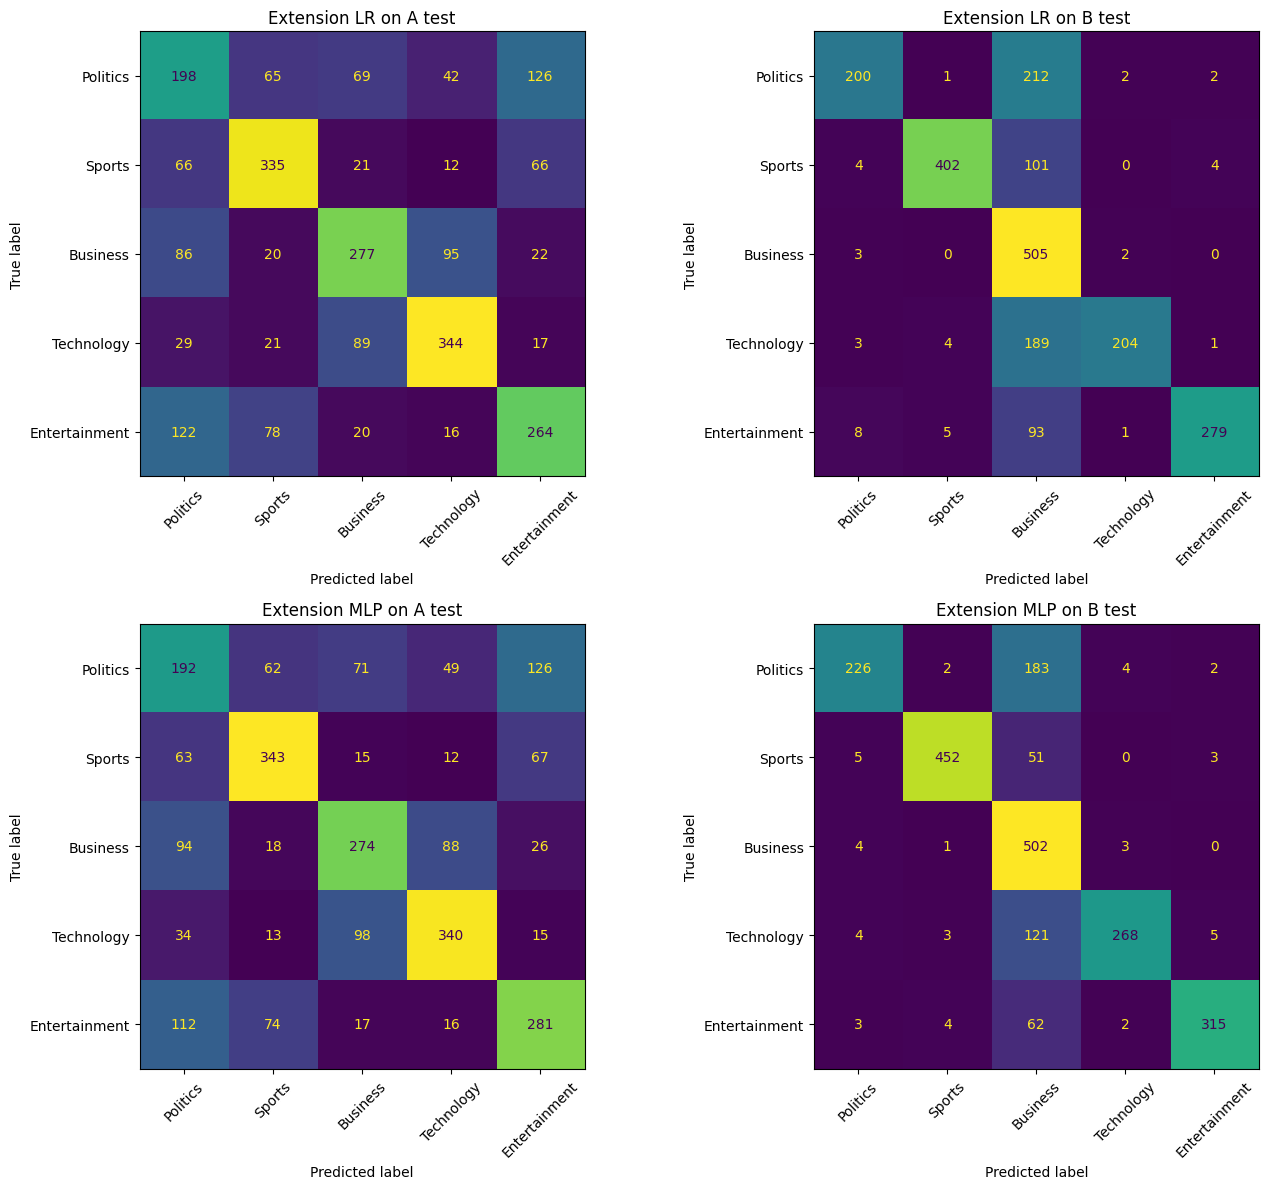

In [29]:
# Per-class F1, required vs extension, on A test and B test
rows = []
for tag in ["lr", "mlp"]:
    for lab in CLASS_IDS:
        row = {"model": tag.upper(), "label": lab, "class": LABELS.loc[lab, "Set A"]}
        for ds in ["A_test", "B_test"]:
            base = final_results[tag][ds]["per_class"][str(lab)]["f1-score"]
            ext = ext_final_results[tag][ds]["per_class"][str(lab)]["f1-score"]
            row[f"{ds}_f1_unigram"], row[f"{ds}_f1_bigram"], row[f"{ds}_f1_change"] = base, ext, ext - base
        rows.append(row)
p3_class_compare = pd.DataFrame(rows)
p3_class_compare.to_csv("results/extension/part3_per_class_comparison.csv", index=False)
display(p3_class_compare.round(3))

# Extension confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for i, tag in enumerate(["lr", "mlp"]):
    for j, ds in enumerate(["A_test", "B_test"]):
        cm = np.array(ext_final_results[tag][ds]["confusion_matrix"])
        ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=axes[i, j], colorbar=False, xticks_rotation=45)
        axes[i, j].set_title(f"Extension {tag.upper()} on {ds.replace('_', ' ')}")
plt.tight_layout()
plt.savefig("results/extension/confusion_matrices.png", dpi=150)
plt.show()

In [30]:
# Error-type changes: (extension confusion matrix) - (required confusion matrix)
# Off-diagonal positive = the extension makes more of that mistake. Negative = fewer.
for tag in ["lr", "mlp"]:
    for ds in ["A_test", "B_test"]:
        diff = (np.array(ext_final_results[tag][ds]["confusion_matrix"])
                - np.array(final_results[tag][ds]["confusion_matrix"]))
        print(f"\n{tag.upper()} {ds}: rows = true class, columns = predicted class")
        display(pd.DataFrame(diff, index=class_names, columns=class_names))


LR A_test: rows = true class, columns = predicted class


,Politics,Sports,Business,Technology,Entertainment
Politics,11,5,-2,-1,-13
Sports,5,3,7,3,-18
Business,-2,4,-5,6,-3
Technology,-3,-2,10,2,-7
Entertainment,2,0,5,-2,-5



LR B_test: rows = true class, columns = predicted class


,Politics,Sports,Business,Technology,Entertainment
Politics,-26,0,26,0,0
Sports,2,-43,40,0,1
Business,0,0,0,0,0
Technology,0,1,54,-54,-1
Entertainment,1,1,21,0,-23



MLP A_test: rows = true class, columns = predicted class


,Politics,Sports,Business,Technology,Entertainment
Politics,6,2,-1,3,-10
Sports,10,-5,0,1,-6
Business,16,-2,-2,-23,11
Technology,10,-2,27,-34,-1
Entertainment,-7,-5,0,-7,19



MLP B_test: rows = true class, columns = predicted class


,Politics,Sports,Business,Technology,Entertainment
Politics,31,1,-35,2,1
Sports,2,-6,3,0,1
Business,1,1,-1,-1,0
Technology,2,-1,25,-31,5
Entertainment,-17,1,23,-14,7


### Extension, Part 3 redo (post hoc): every setting on the test sets
Analysis only. Not used for selection.

In [31]:
ext_posthoc = []
for name, (kind, setting) in ALL_SETTINGS.items():
    model, _, _ = train_model(kind, setting, Xe_a_full, y_a_full, epochs=ext_best_epochs[name])
    fa = evaluate(y_a_test, predict(model, Xe_a_test))["macro_f1"]
    fb = evaluate(y_b_test, predict(model, Xe_b_test))["macro_f1"]
    ext_posthoc.append({"setting": name, "model": kind.upper(),
                        "A_test_macro_f1": fa, "B_test_macro_f1": fb, "A_minus_B": fa - fb})
ext_posthoc_df = pd.DataFrame(ext_posthoc)
ext_posthoc_df.to_csv("results/extension/posthoc_all_settings.csv", index=False)
display(ext_posthoc_df.round(4))

,setting,model,A_test_macro_f1,B_test_macro_f1,A_minus_B
0,lr_wd0,LR,0.5625,0.7308,-0.1683
1,lr_wd1e-5,LR,0.5667,0.7255,-0.1589
2,lr_wd1e-4,LR,0.5589,0.6866,-0.1277
3,lr_wd1e-3,LR,0.5418,0.4039,0.1379
4,mlp_none,MLP,0.5822,0.7874,-0.2052
5,mlp_dropout,MLP,0.5715,0.7988,-0.2273
6,mlp_dropout_wd,MLP,0.5693,0.7163,-0.1470
7,mlp_strong,MLP,0.5552,0.7135,-0.1584


### Extension, Part 5 redo: add limited Data C examples
Same budgets, strategies, sampling procedure, and seeds as Part 5. Budget 0 is the extension's Part 3 model.

In [32]:
EXT_FINAL = {
    "lr":  {"kind": "lr", "name": ext_best_lr, "setting": ALL_SETTINGS[ext_best_lr][1],
            "epochs": ext_best_epochs[ext_best_lr]},
    "mlp": {"kind": "mlp", "name": ext_best_mlp, "setting": ALL_SETTINGS[ext_best_mlp][1],
            "epochs": ext_best_epochs[ext_best_mlp]},
}

ext_rows, ext_conf_mats = [], {}
for tag, cfg in EXT_FINAL.items():
    met, cm = part5_metrics(EXT_FINAL_MODELS[tag], ext_vec_full)
    ext_rows.append({"model": tag.upper(), "strategy": "baseline", "budget": 0, "c_counts": "{}",
                     "train_size": len(SOURCE_A_TRAIN), "vocab_size": len(ext_vec_full.vocabulary_), **met})
    ext_conf_mats[f"{tag}_baseline_0"] = cm
    print(f"{tag.upper()} baseline: C macro-F1={met['C_macro_f1_1to4']:.4f}  C label-1 F1={met['C_label1_f1']:.4f}")

    for strategy in STRATEGIES:
        for budget in BUDGETS:
            c_sample, counts = sample_c(budget, strategy)
            train_df = pd.concat([SOURCE_A_TRAIN, c_sample], ignore_index=True)
            vec = make_ext_vec()  # refit on A train + selected C examples
            X = vec.fit_transform(article_text(train_df))
            model, _, _ = train_model(cfg["kind"], cfg["setting"], X, train_df["Label"].to_numpy(),
                                      epochs=cfg["epochs"])
            met, cm = part5_metrics(model, vec)
            ext_rows.append({"model": tag.upper(), "strategy": strategy, "budget": budget,
                             "c_counts": str(counts), "train_size": len(train_df),
                             "vocab_size": len(vec.vocabulary_), **met})
            ext_conf_mats[f"{tag}_{strategy}_{budget}"] = cm
            print(f"{tag.upper()} {strategy:12s} {budget:5d}  C macro-F1={met['C_macro_f1_1to4']:.4f}  "
                  f"C label-1 F1={met['C_label1_f1']:.4f}  A={met['A_test_macro_f1']:.4f}  B={met['B_test_macro_f1']:.4f}")

ext_results_df = pd.DataFrame(ext_rows)
ext_results_df.to_csv("results/extension/part5_all_conditions.csv", index=False)
with open("results/extension/part5_confusion_matrices.json", "w") as f:
    json.dump(ext_conf_mats, f)

for tag in ["LR", "MLP"]:
    print(f"\n===== Extension {tag} =====")
    display(ext_results_df[ext_results_df.model == tag][["strategy", "budget", "train_size", "vocab_size"] + METRIC_COLS]
            .round(4).reset_index(drop=True))

ext_check = ext_results_df[ext_results_df.budget > 0]
print("All extension adapted models pass 40% C macro-F1:", bool((ext_check["C_macro_f1_1to4"] >= 0.40).all()))

LR baseline: C macro-F1=0.5484  C label-1 F1=0.4822
LR label1_only     50  C macro-F1=0.5553  C label-1 F1=0.5265  A=0.5687  B=0.7257
LR label1_only    150  C macro-F1=0.5508  C label-1 F1=0.5381  A=0.5634  B=0.7525
LR label1_only    600  C macro-F1=0.5374  C label-1 F1=0.5538  A=0.5623  B=0.7470
LR label1_only   1500  C macro-F1=0.5156  C label-1 F1=0.5371  A=0.5596  B=0.7269
LR shared_only     50  C macro-F1=0.5415  C label-1 F1=0.4525  A=0.5679  B=0.7255
LR shared_only    150  C macro-F1=0.5430  C label-1 F1=0.4267  A=0.5694  B=0.7537
LR shared_only    600  C macro-F1=0.5498  C label-1 F1=0.3785  A=0.5725  B=0.7717
LR shared_only   1500  C macro-F1=0.5538  C label-1 F1=0.3501  A=0.5732  B=0.7773
LR balanced        50  C macro-F1=0.5512  C label-1 F1=0.4942  A=0.5685  B=0.7297
LR balanced       150  C macro-F1=0.5673  C label-1 F1=0.5191  A=0.5674  B=0.7580
LR balanced       600  C macro-F1=0.5985  C label-1 F1=0.5650  A=0.5701  B=0.7800
LR balanced      1500  C macro-F1=0.6082  C la

,strategy,budget,train_size,vocab_size,C_label1_recall,C_label1_f1,C_macro_f1_1to4,C_strict_macro_f1_2to4,C_shared_only_macro_f1_2to4,C_pct_pred_label5,A_test_macro_f1,B_test_macro_f1
0,baseline,0,7500,31068,0.406,0.4822,0.5484,0.5705,0.6197,5.40,0.5667,0.7255
1,label1_only,50,7550,31320,0.536,0.5265,0.5553,0.5649,0.6048,4.75,0.5687,0.7257
2,label1_only,150,7650,31873,0.614,0.5381,0.5508,0.5551,0.5894,4.25,0.5634,0.7525
3,label1_only,600,8100,34338,0.720,0.5538,0.5374,0.5319,0.5574,3.60,0.5623,0.7470
4,label1_only,1500,9000,39078,0.768,0.5371,0.5156,0.5085,0.5300,2.75,0.5596,0.7269
5,shared_only,50,7550,31297,0.362,0.4525,0.5415,0.5712,0.6251,4.70,0.5679,0.7255
6,shared_only,150,7650,31761,0.332,0.4267,0.5430,0.5818,0.6395,4.30,0.5694,0.7537
7,shared_only,600,8100,33948,0.268,0.3785,0.5498,0.6068,0.6742,3.00,0.5725,0.7717
8,shared_only,1500,9000,38552,0.236,0.3501,0.5538,0.6217,0.6948,2.55,0.5732,0.7773
9,balanced,50,7550,31298,0.428,0.4942,0.5512,0.5701,0.6187,4.90,0.5685,0.7297



===== Extension MLP =====


,strategy,budget,train_size,vocab_size,C_label1_recall,C_label1_f1,C_macro_f1_1to4,C_strict_macro_f1_2to4,C_shared_only_macro_f1_2to4,C_pct_pred_label5,A_test_macro_f1,B_test_macro_f1
0,baseline,0,7500,31068,0.422,0.4862,0.5447,0.5642,0.6115,6.95,0.5715,0.7988
1,label1_only,50,7550,31320,0.552,0.5217,0.5507,0.5603,0.5996,4.65,0.5810,0.8016
2,label1_only,150,7650,31873,0.636,0.5381,0.5484,0.5518,0.5847,4.00,0.5688,0.8376
3,label1_only,600,8100,34338,0.694,0.5376,0.5150,0.5075,0.5344,3.80,0.5689,0.7207
4,label1_only,1500,9000,39078,0.756,0.5408,0.5246,0.5192,0.5415,3.20,0.5691,0.8127
5,shared_only,50,7550,31297,0.388,0.4636,0.5474,0.5754,0.6279,6.55,0.5806,0.7955
6,shared_only,150,7650,31761,0.368,0.4386,0.5360,0.5685,0.6233,5.50,0.5652,0.7826
7,shared_only,600,8100,33948,0.330,0.4331,0.5685,0.6136,0.6760,2.95,0.5790,0.8002
8,shared_only,1500,9000,38552,0.292,0.4022,0.5742,0.6315,0.7012,2.15,0.5823,0.8250
9,balanced,50,7550,31298,0.454,0.4994,0.5564,0.5753,0.6214,6.05,0.5773,0.7972


All extension adapted models pass 40% C macro-F1: True


### Extension vs required: Part 5 comparison

In [33]:
KEY = ["model", "strategy", "budget"]
SHOW = ["C_label1_f1", "C_macro_f1_1to4", "C_strict_macro_f1_2to4", "A_test_macro_f1", "B_test_macro_f1"]
p5_compare = results_df[KEY + SHOW].merge(ext_results_df[KEY + SHOW], on=KEY, suffixes=("_unigram", "_bigram"))
for m in SHOW:
    p5_compare[f"{m}_change"] = p5_compare[f"{m}_bigram"] - p5_compare[f"{m}_unigram"]
p5_compare.to_csv("results/extension/part5_comparison.csv", index=False)
display(p5_compare[KEY + [f"{m}_{s}" for m in ["C_label1_f1", "C_macro_f1_1to4"] for s in ["unigram", "bigram", "change"]]
                   + [f"{m}_change" for m in ["A_test_macro_f1", "B_test_macro_f1"]]].round(4))

,model,strategy,budget,C_label1_f1_unigram,C_label1_f1_bigram,C_label1_f1_change,C_macro_f1_1to4_unigram,C_macro_f1_1to4_bigram,C_macro_f1_1to4_change,A_test_macro_f1_change,B_test_macro_f1_change
0,LR,baseline,0,0.4983,0.4822,-0.0161,0.5608,0.5484,-0.0124,0.0019,-0.0633
1,LR,label1_only,50,0.5406,0.5265,-0.0141,0.5657,0.5553,-0.0104,0.0065,-0.0748
2,LR,label1_only,150,0.5512,0.5381,-0.0131,0.5609,0.5508,-0.0101,0.0040,-0.0534
3,LR,label1_only,600,0.5535,0.5538,0.0004,0.5450,0.5374,-0.0076,0.0109,-0.0713
4,LR,label1_only,1500,0.5403,0.5371,-0.0032,0.5299,0.5156,-0.0142,0.0102,-0.0697
5,LR,shared_only,50,0.4904,0.4525,-0.0379,0.5553,0.5415,-0.0138,0.0022,-0.0716
6,LR,shared_only,150,0.4631,0.4267,-0.0363,0.5532,0.5430,-0.0102,0.0020,-0.0492
7,LR,shared_only,600,0.4203,0.3785,-0.0418,0.5681,0.5498,-0.0184,0.0032,-0.0395
8,LR,shared_only,1500,0.3628,0.3501,-0.0127,0.5609,0.5538,-0.0071,-0.0022,-0.0290
9,LR,balanced,50,0.5174,0.4942,-0.0232,0.5584,0.5512,-0.0073,0.0038,-0.0692


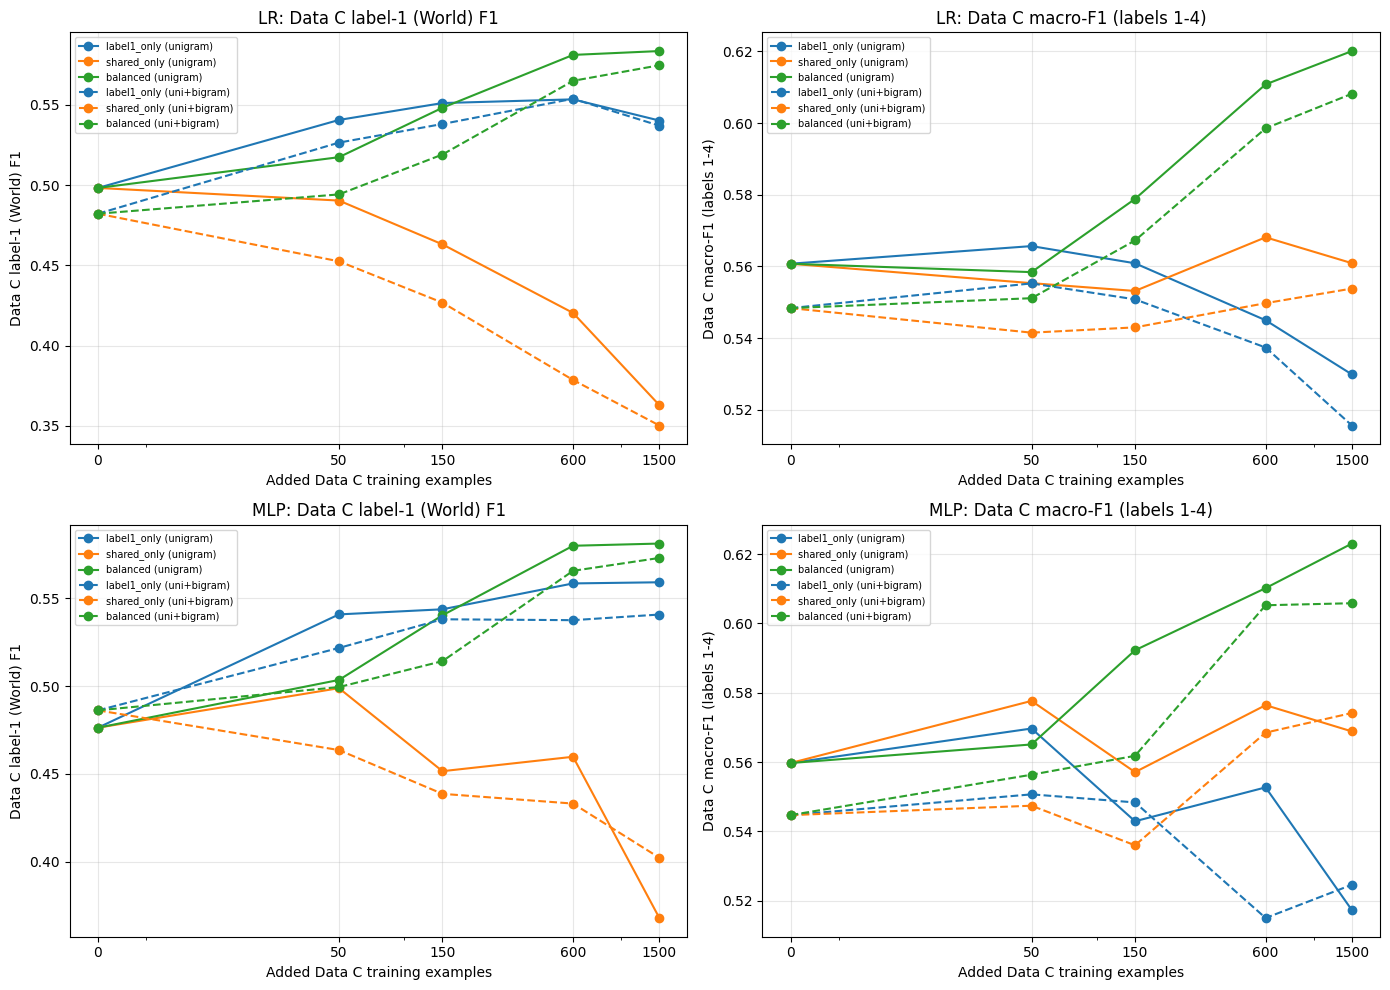

In [34]:
# Required (solid) vs extension (dashed), per strategy
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
colors = dict(zip(STRATEGIES, ["tab:blue", "tab:orange", "tab:green"]))
for i, tag in enumerate(["LR", "MLP"]):
    for j, (metric, label) in enumerate([("C_label1_f1", "Data C label-1 (World) F1"),
                                         ("C_macro_f1_1to4", "Data C macro-F1 (labels 1-4)")]):
        ax = axes[i, j]
        for df, style, rep in [(results_df, "-", "unigram"), (ext_results_df, "--", "uni+bigram")]:
            d = df[df.model == tag]
            base = d[d.budget == 0].iloc[0]
            for s in STRATEGIES:
                ds = d[d.strategy == s].sort_values("budget")
                ax.plot([0] + ds.budget.tolist(), [base[metric]] + ds[metric].tolist(),
                        linestyle=style, marker="o", color=colors[s], label=f"{s} ({rep})")
        ax.set_xscale("symlog", linthresh=50)
        ax.set_xticks(TICKS)
        ax.set_xticklabels(TICKS)
        ax.set_xlabel("Added Data C training examples")
        ax.set_ylabel(label)
        ax.set_title(f"{tag}: {label}")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig("results/extension/part5_comparison_curves.png", dpi=150)
plt.show()

In [35]:
# Where true Data C World (label 1) articles go, required vs extension Part 3 models
rows = []
for tag in ["lr", "mlp"]:
    for rep, cms in [("unigram", conf_mats), ("uni+bigram", ext_conf_mats)]:
        world_row = np.array(cms[f"{tag}_baseline_0"])[0]  # true label 1
        rows.append({"model": tag.upper(), "representation": rep,
                     **{f"pred_{LABELS.loc[l, 'Set A']}": int(world_row[l - 1]) for l in CLASS_IDS}})
display(pd.DataFrame(rows))

,model,representation,pred_Politics,pred_Sports,pred_Business,pred_Technology,pred_Entertainment
0,LR,unigram,215,72,127,32,54
1,LR,uni+bigram,203,69,156,33,39
2,MLP,unigram,196,59,161,42,42
3,MLP,uni+bigram,211,65,143,37,44
